In [7]:
# Core data-handling and plotting libraries
import warnings, os
warnings.filterwarnings("ignore")      # keep the notebook output clean
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# Scikit-learn: preprocessing, models, validation and metrics
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [8]:
DATA_DIR =r"C:\Users\ABHI\OneDrive - SRH\Desktop\Group %_advance programming\cardata"  # folder holding the per-brand CSV files

# The nine clean, standard-schema brand files (we skip the redundant/unclean extras)
brands = ["audi", "bmw", "ford", "hyundi", "merc",
          "skoda", "toyota", "vauxhall", "vw"]

frames = []
for b in brands:
    df = pd.read_csv(os.path.join(DATA_DIR, b + ".csv"))
    df.columns = [c.strip() for c in df.columns]   # remove stray header whitespace
    df = df.rename(columns={"tax(£)": "tax"})       # unify the tax column name
    df["brand"] = b                                  # keep track of the car's brand
    frames.append(df)

data = pd.concat(frames, ignore_index=True)          # stack all brands into one table
print("Merged dataset shape:", data.shape)
data.head(99187)

Merged dataset shape: (99187, 10)


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,brand
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4,audi
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0,audi
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4,audi
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0,audi
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0,audi
...,...,...,...,...,...,...,...,...,...,...
99182,Eos,2012,5990,Manual,74000,Diesel,125,58.9,2.0,vw
99183,Fox,2008,1799,Manual,88102,Petrol,145,46.3,1.2,vw
99184,Fox,2009,1590,Manual,70000,Petrol,200,42.0,1.4,vw
99185,Fox,2006,1250,Manual,82704,Petrol,150,46.3,1.2,vw


In [9]:
df.isna().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
brand           0
dtype: int64

In [10]:
data.info()                       # column names, non-null counts and data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99187 entries, 0 to 99186
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         99187 non-null  object 
 1   year          99187 non-null  int64  
 2   price         99187 non-null  int64  
 3   transmission  99187 non-null  object 
 4   mileage       99187 non-null  int64  
 5   fuelType      99187 non-null  object 
 6   tax           99187 non-null  int64  
 7   mpg           99187 non-null  float64
 8   engineSize    99187 non-null  float64
 9   brand         99187 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 7.6+ MB


In [11]:
data.describe()                   # summary statistics for the numeric columns

,year,price,mileage,tax,mpg,engineSize
count,99187.000000,99187.000000,99187.000000,99187.000000,99187.000000,99187.000000
mean,2017.087723,16805.347656,23058.914213,120.299838,55.166825,1.663280
std,2.123934,9866.773417,21148.523721,63.150926,16.138522,0.557646
min,1970.000000,450.000000,1.000000,0.000000,0.300000,0.000000
25%,2016.000000,9999.000000,7425.000000,125.000000,47.100000,1.200000
50%,2017.000000,14495.000000,17460.000000,145.000000,54.300000,1.600000
75%,2019.000000,20870.000000,32339.000000,145.000000,62.800000,2.000000
max,2060.000000,159999.000000,323000.000000,580.000000,470.800000,6.600000


In [12]:
# Data-quality checks
print("Missing values per column:")
print(data.isnull().sum())
print("\nDuplicate rows:", data.duplicated().sum())

Missing values per column:
model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
brand           0
dtype: int64

Duplicate rows: 1475


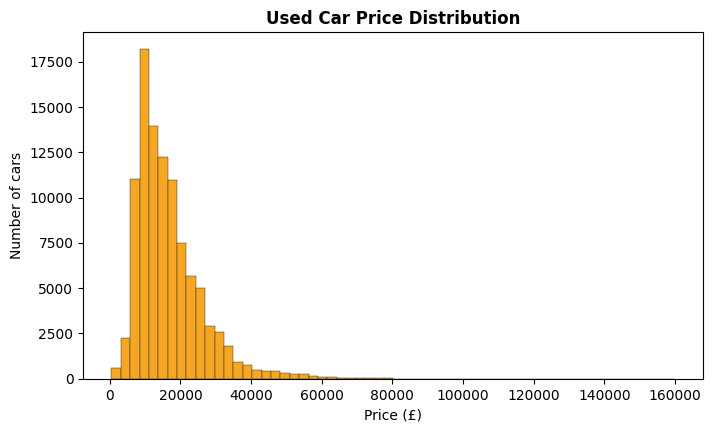

In [13]:
# Distribution of the target variable: car price
plt.figure(figsize=(8, 4.5))
plt.hist(data["price"], bins=60, color="#F5A623", edgecolor="#1A1D21", linewidth=0.3)
plt.title("Used Car Price Distribution", fontweight="bold")
plt.xlabel("Price (£)"); plt.ylabel("Number of cars")
plt.show()

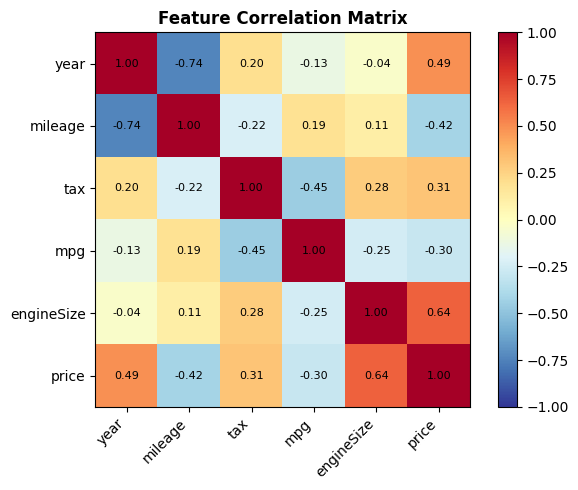

In [14]:
# Correlation of numeric features with price
num_cols = ["year", "mileage", "tax", "mpg", "engineSize", "price"]
corr = data[num_cols].corr()

plt.figure(figsize=(6.5, 5))
im = plt.imshow(corr, cmap="RdYlBu_r", vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046)
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Feature Correlation Matrix", fontweight="bold")
plt.tight_layout(); plt.show()

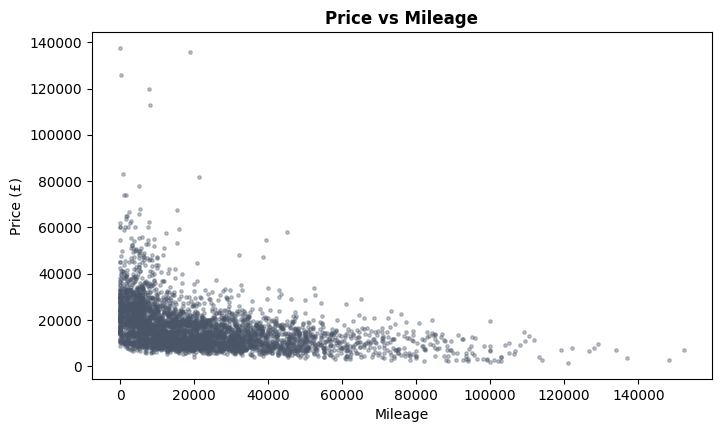

In [15]:
# How price varies with mileage (sample for readability)
sample = data.sample(4000, random_state=1)
plt.figure(figsize=(8, 4.5))
plt.scatter(sample["mileage"], sample["price"], s=6, alpha=0.35, color="#4A5568")
plt.title("Price vs Mileage", fontweight="bold")
plt.xlabel("Mileage"); plt.ylabel("Price (£)")
plt.show()

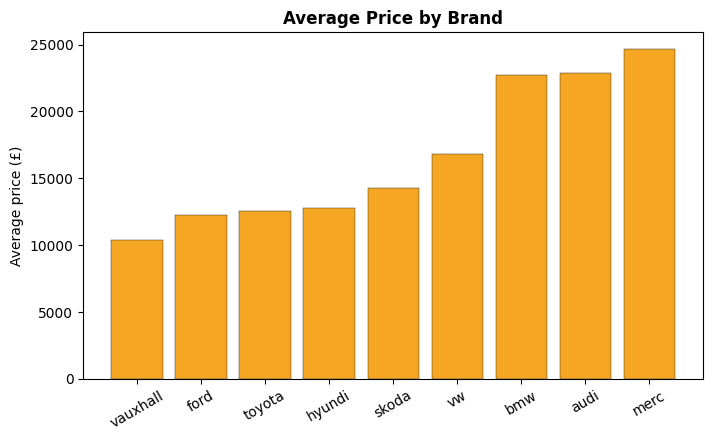

In [16]:
# Average price per brand
brand_price = data.groupby("brand")["price"].mean().sort_values()
plt.figure(figsize=(8, 4.5))
plt.bar(brand_price.index, brand_price.values, color="#F5A623", edgecolor="#1A1D21", linewidth=0.3)
plt.title("Average Price by Brand", fontweight="bold")
plt.ylabel("Average price (£)"); plt.xticks(rotation=30)
plt.show()

In [17]:
# --- Cleaning: remove duplicates and physically impossible values ---
before = len(data)
data = data.drop_duplicates()                                  # exact duplicate listings
data = data[(data["year"] >= 1990) & (data["year"] <= 2024)]   # drop invalid years (e.g. 2060)
data = data[data["price"] > 0]                                 # price must be positive
data = data[data["engineSize"] > 0]                            # 0.0 engine size = missing spec
print(f"Rows: {before} -> {len(data)} after cleaning")

Rows: 99187 -> 97442 after cleaning


In [18]:
# --- Define the input features (X) and the target (y) ---
num_features = ["year", "mileage", "tax", "mpg", "engineSize"]   # numeric inputs
cat_features = ["brand", "transmission", "fuelType"]             # categorical inputs
X = data[num_features + cat_features]
y = data["price"]                                               # target: price

# Numeric pipeline: fill any missing value with the median, then standardise
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])
# Categorical pipeline: fill missing with the most frequent value, then one-hot encode
categoric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
# Combine both into a single preprocessor applied column-wise
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_features),
    ("cat", categoric_pipe, cat_features),
])
print("Preprocessing pipeline ready.")

Preprocessing pipeline ready.


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)   # random_state makes the split reproducible
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 77953 | Test rows: 19489


In [20]:
# Three models: a simple baseline and two stronger ensemble models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest":     RandomForestRegressor(n_estimators=120, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)   # 5-fold cross-validation
results = {}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])   # preprocessing + model
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1)

    pipe.fit(X_train, y_train)                 # train on the full training set
    pred = pipe.predict(X_test)                # predict on unseen test cars

    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae  = mean_absolute_error(y_test, pred)
    r2   = r2_score(y_test, pred)
    results[name] = {"cv_r2": cv_r2.mean(), "rmse": rmse, "mae": mae, "r2": r2, "pipe": pipe}

    print(f"{name:<20} CV R2={cv_r2.mean():.3f} | Test R2={r2:.3f} "
          f"| RMSE=£{rmse:,.0f} | MAE=£{mae:,.0f}")

Linear Regression    CV R2=0.780 | Test R2=0.778 | RMSE=£4,647 | MAE=£2,874
Random Forest        CV R2=0.941 | Test R2=0.935 | RMSE=£2,512 | MAE=£1,334
Gradient Boosting    CV R2=0.928 | Test R2=0.932 | RMSE=£2,581 | MAE=£1,644


In [21]:
# Summary table
summary = pd.DataFrame({
    "CV R2":  [results[m]["cv_r2"] for m in results],
    "Test R2":[results[m]["r2"]   for m in results],
    "RMSE (£)":[results[m]["rmse"] for m in results],
    "MAE (£)": [results[m]["mae"]  for m in results],
}, index=results.keys()).round(3)
summary

,CV R2,Test R2,RMSE (£),MAE (£)
Linear Regression,0.780,0.778,4646.642,2873.522
Random Forest,0.941,0.935,2512.348,1333.896
Gradient Boosting,0.928,0.932,2581.065,1643.990


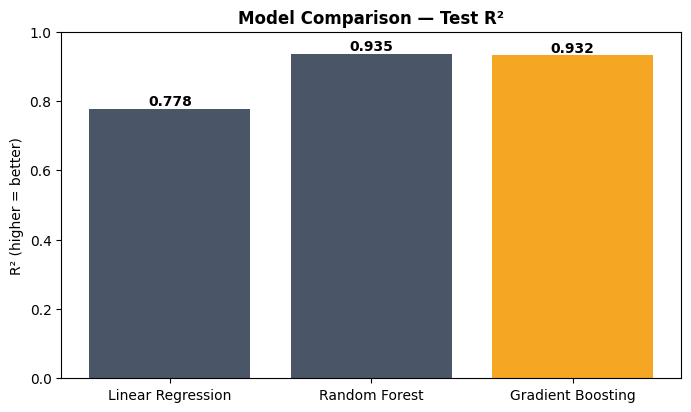

In [24]:
# Visual comparison of test R2
names = list(results.keys())
r2s = [results[n]["r2"] for n in names]
plt.figure(figsize=(8, 4.5))
bars = plt.bar(names, r2s, color=["#4A5568", "#4A5568", "#F5A623"])
for bar, v in zip(bars, r2s):
    plt.text(bar.get_x()+bar.get_width()/2, v+0.01, f"{v:.3f}", ha="center", fontweight="bold")
plt.ylim(0, 1); plt.ylabel("R² (higher = better)")
plt.title("Model Comparison — Test R²", fontweight="bold")
plt.show()

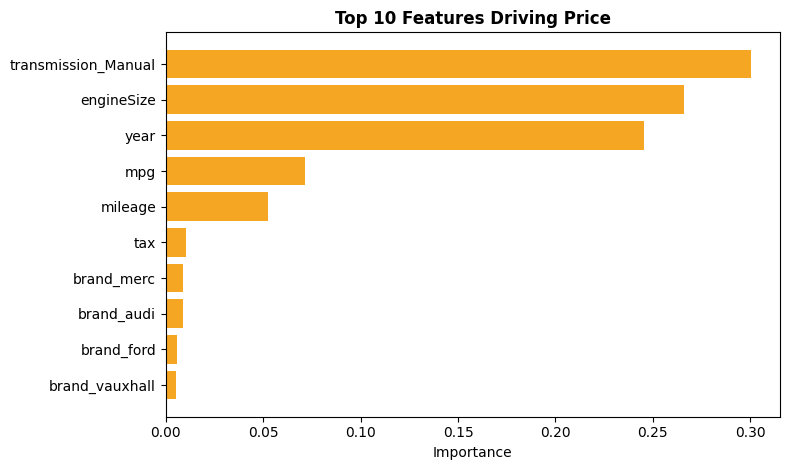

In [23]:
rf = results["Random Forest"]["pipe"]
ohe = rf.named_steps["prep"].named_transformers_["cat"].named_steps["onehot"]
feat_names = num_features + list(ohe.get_feature_names_out(cat_features))
imp = rf.named_steps["model"].feature_importances_

order = np.argsort(imp)[::-1][:10]        # top 10 features
plt.figure(figsize=(8, 4.8))
plt.barh([feat_names[i] for i in order][::-1], [imp[i] for i in order][::-1], color="#F5A623")
plt.title("Top 10 Features Driving Price", fontweight="bold")
plt.xlabel("Importance") 
plt.tight_layout()
plt.show()